# 01 · Data quality & the observation clock

Are we comparing returns over exactly the same economic interval?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## Data contract

QQQ is the Nasdaq-100 ETF proxy. Its adjusted close includes distribution and split adjustments;
raw close is retained for sizing. Coinbase hourly bars are keyed by their **start** time.
At a 20:00 UTC equity close, we use the close of the 19:00–20:00 bar, never the 20:00–21:00 bar.
The same rule handles 21:00 UTC winter closes and early closes. Exact lookups fail on missing bars.

Coinbase's candle close is the last trade within that hour, an approximation to a simultaneous
closing mark. These are research marks, not executable bid/ask quotes. No missing observations
are forward-filled. See the [Coinbase candle specification](https://docs.cdp.coinbase.com/api-reference/exchange-api/rest-api/products/get-product-candles)
and [exchange-calendar documentation](https://pandas-market-calendars.readthedocs.io/en/latest/usage.html).

,sessions_flagged
btc_missing,0
qqq_missing,0
nonpositive,0
early_close,18
multi_day_interval,485


,close_utc,btc,qqq,qqq_raw,elapsed_days
session,,,,,
2026-10-28,2026-10-28 20:00:00+00:00,"81,502.0900",725.6100,725.6100,1.0000
2026-10-29,2026-10-29 20:00:00+00:00,"80,743.2900",715.3400,715.3400,1.0000
2026-10-30,2026-10-30 20:00:00+00:00,"76,715.4000",690.4900,690.4900,1.0000
2026-11-02,2026-11-02 21:00:00+00:00,"76,641.3600",681.0900,681.0900,3.0417
2026-11-03,2026-11-03 21:00:00+00:00,"77,784.2500",685.2800,685.2800,1.0000
2026-11-04,2026-11-04 21:00:00+00:00,"80,044.0100",691.9500,691.9500,1.0000
2026-11-05,2026-11-05 21:00:00+00:00,"76,085.0500",647.0500,647.0500,1.0000
2026-11-06,2026-11-06 21:00:00+00:00,"75,769.9400",656.1000,656.1000,1.0000


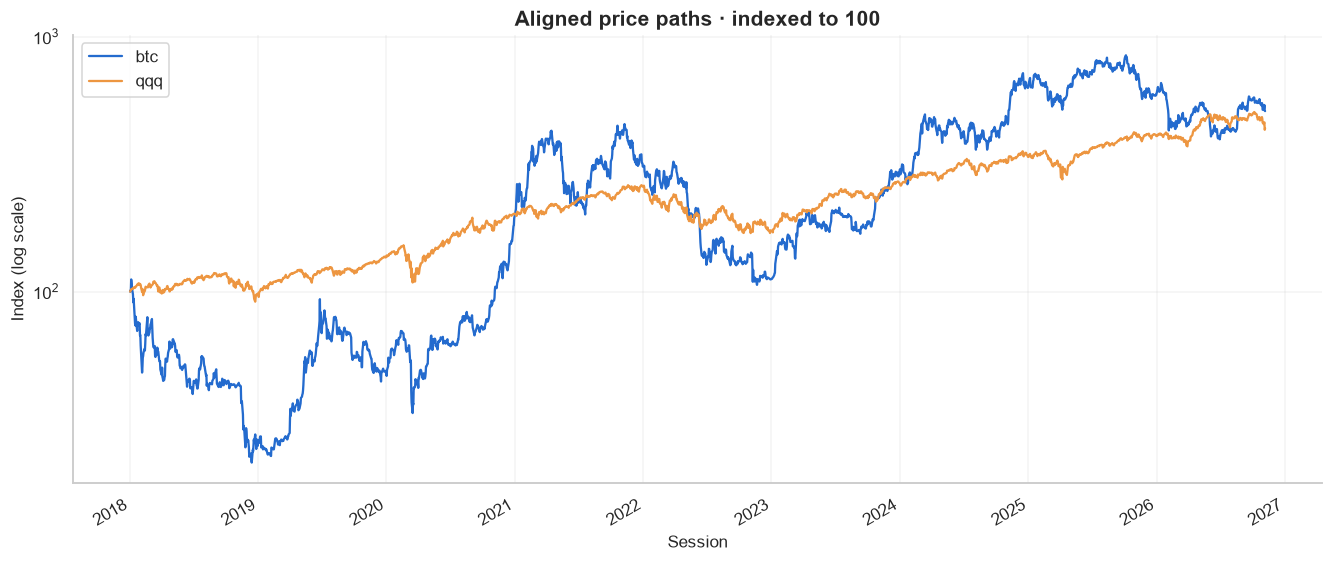

In [2]:
audit = pd.read_parquet(ROOT / "data/processed/alignment_audit.parquet")
display(audit.sum().to_frame("sessions_flagged"))
display(prices[["close_utc", "btc", "qqq", "qqq_raw", "elapsed_days"]].tail(8))
assert not audit[["btc_missing", "qqq_missing", "nonpositive"]].any().any()
assert prices.index.is_unique and prices.index.is_monotonic_increasing
fig, ax = plt.subplots(figsize=(12, 5))
(prices[["btc", "qqq"]] / prices[["btc", "qqq"]].iloc[0] * 100).plot(ax=ax, logy=True)
ax.set(title="Aligned price paths · indexed to 100", ylabel="Index (log scale)", xlabel="Session")
save_figure(fig, ROOT, "01_price_paths")
plt.show()

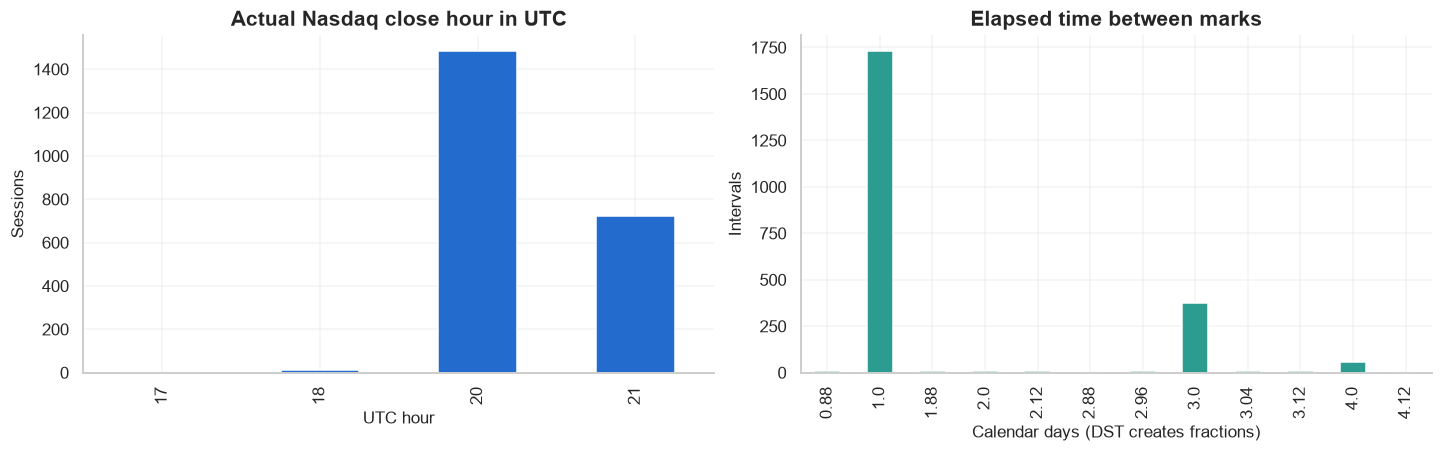

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
prices.close_utc.dt.hour.value_counts().sort_index().plot.bar(ax=axes[0], color=PALETTE[0])
axes[0].set(title="Actual Nasdaq close hour in UTC", xlabel="UTC hour", ylabel="Sessions")
prices.elapsed_days.dropna().round(2).value_counts().sort_index().plot.bar(ax=axes[1], color=PALETTE[2])
axes[1].set(title="Elapsed time between marks", xlabel="Calendar days (DST creates fractions)", ylabel="Intervals")
plt.show()

## Quantify the UTC-date mismatch

The deliberately misaligned series below uses Bitcoin's UTC end-of-day mark with the same date
label as QQQ. That BTC mark is several hours **after** QQQ closes. It is a diagnostic comparator
only and never feeds the hedge or backtest. Reindex prices before computing returns so Monday's
BTC return includes the weekend, rather than comparing one crypto day with three equity days.

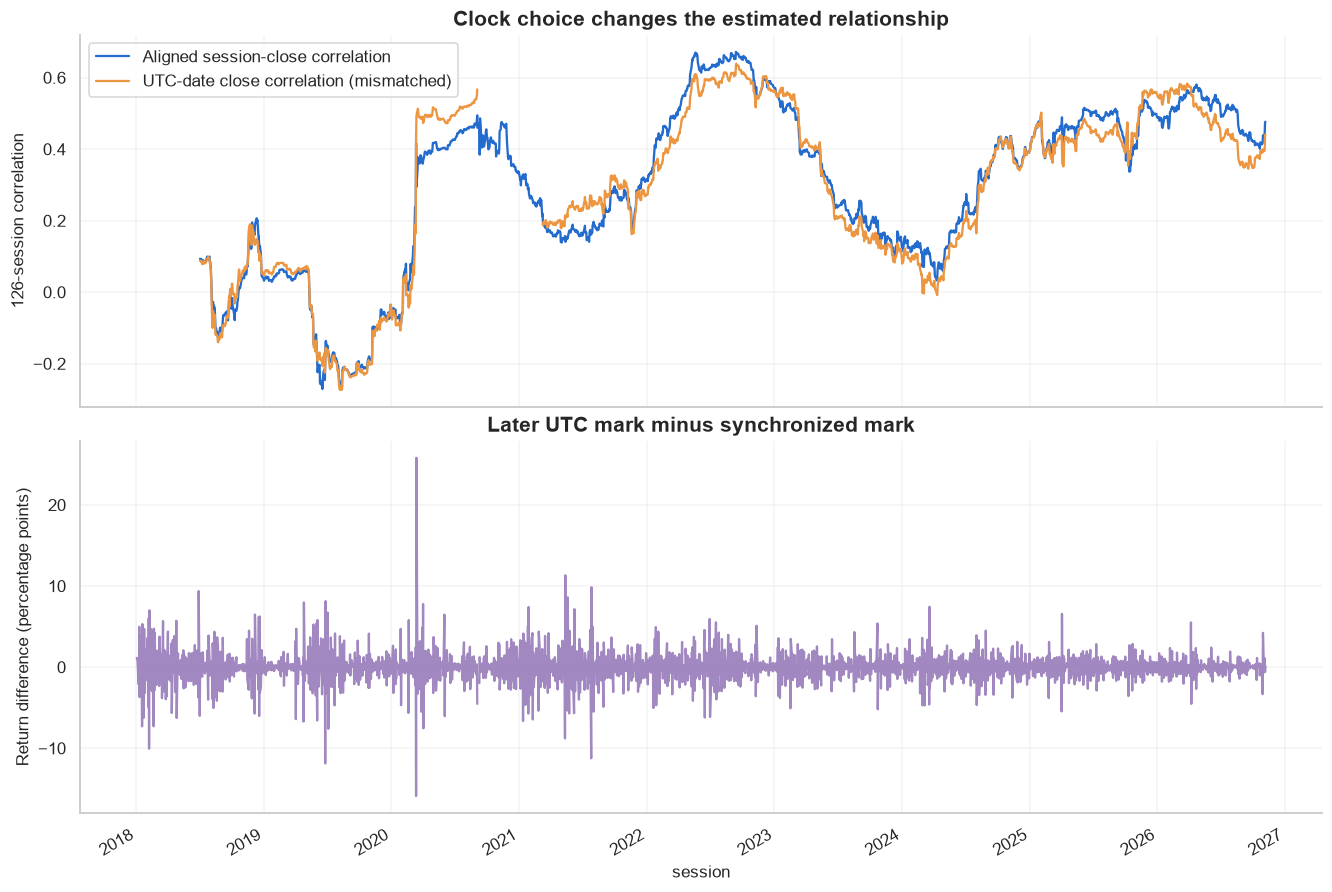

In [4]:
naive = prices.btc_utc_close.pct_change(fill_method=None).reindex(returns.index)
clock_comparison = pd.DataFrame({
    "Aligned session-close correlation": returns.btc.rolling(126).corr(returns.qqq),
    "UTC-date close correlation (mismatched)": naive.rolling(126).corr(returns.qqq),
})
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
clock_comparison.plot(ax=axes[0])
axes[0].set(title="Clock choice changes the estimated relationship", ylabel="126-session correlation")
((naive - returns.btc) * 100).plot(ax=axes[1], color=PALETTE[3], alpha=.8)
axes[1].set(ylabel="Return difference (percentage points)", title="Later UTC mark minus synchronized mark")
plt.show()

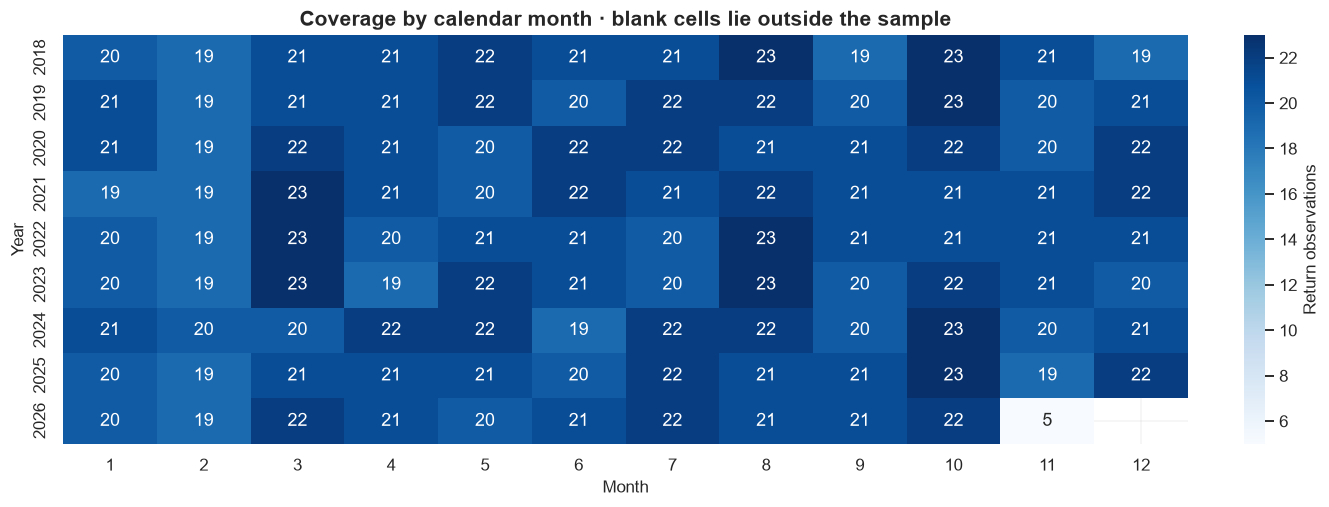

,count,mean,std,min,1%,5%,50%,95%,99%,max
btc,"2,224.0000",0.0015,0.0397,-0.2291,-0.1119,-0.0572,0.0004,0.0650,0.1125,0.2393
qqq,"2,224.0000",0.0008,0.0150,-0.1198,-0.0409,-0.0243,0.0013,0.0222,0.0360,0.1200


In [5]:
quality = returns.assign(year=returns.index.year, month=returns.index.month)
counts = quality.groupby(["year", "month"]).btc.count().unstack()
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(counts, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "Return observations"})
ax.set(title="Coverage by calendar month · blank cells lie outside the sample", xlabel="Month", ylabel="Year")
plt.show()
display(returns.describe(percentiles=[.01, .05, .5, .95, .99]).T)

**Interpretation:** a clean join is necessary but not sufficient for tradability. Overnight and
weekend gaps, stale quotes, adjusted-price revisions, Coinbase venue basis and unavailable historical
spreads remain. A futures implementation requires contract-level prices, roll rules, funding/margin,
and its own synchronized clock. The hourly archive may have gaps away from the selected close;
the audit proves coverage of our selected marks, not every hour in the archive.

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.